In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
lake = 'lucerne'
folder_path = rf"/storage/alplakes_test/{lake}_100m_2025"
input_folder = os.path.join(folder_path, "outputs_swirl", "eddy_catalogues_final")

In [3]:
lvl0_csv_path = os.path.join(input_folder, "lvl0.csv")

In [4]:
df_lvl0 = pd.read_csv(lvl0_csv_path)
df_lvl0 = df_lvl0.set_index('id', drop=False)
df_lvl0['date'] = pd.to_datetime(df_lvl0['date'])

In [5]:
df = df_lvl0.copy()
df["i_cells"] = df["i_eddy_cells"].map(
    lambda s: np.fromstring(s.strip("[]"), sep=",").astype(int)
)
df["j_cells"] = df["j_eddy_cells"].map(
    lambda s: np.fromstring(s.strip("[]"), sep=",").astype(int)
)

In [6]:
lake_mask = np.load(os.path.join(folder_path, "grid", "mask_lake.npy"))

In [7]:
depths = df_lvl0[['depth_index', 'depth_[m]']].drop_duplicates().sort_values('depth_index').reset_index(drop=True)

In [8]:
Nx=0
Ny=0
if lake == 'lucerne':
    Nx = 288
    Ny = 180
elif lake == 'geneva':
    Nx = 660
    Ny = 245
elif lake == 'neuchatel':
    Nx = 390
    Ny = 96
elif lake == 'zug':
    Nx = 50
    Ny = 140

print(f"Lake: {lake}, Nx: {Nx}, Ny: {Ny}")

Lake: lucerne, Nx: 288, Ny: 180


In [9]:
def set_default_figure_setting():
    plt.rcParams.update({
        "figure.figsize": (10, 2),
        "font.family": "serif",
        "font.serif": ["DejaVu Serif"],
        "axes.grid": False,
        "axes.edgecolor": "#8B8B8B",
        "legend.edgecolor": "#8B8B8B",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.minor.visible": False,
        "ytick.minor.visible": False,
    })

set_default_figure_setting()

# Functions

In [10]:
def get_eddy_cells_snapshot(df, i_time, i_depth_min, i_depth_max, Nx, Ny):
    depth_filter = (
        (df['depth_index'] <= i_depth_max) &
        (df['depth_index'] >= i_depth_min)
    )
    time_filter = df['time_index'] == i_time

    df_filtered = df.loc[depth_filter & time_filter]

    if len(df_filtered) == 0:
        return np.zeros((Nx, Ny)).T

    i_eddies = []
    j_eddies = []
    for _, row in df_filtered.iterrows():
        i = np.fromstring(row['i_eddy_cells'].strip("[]"), sep=',')
        j = np.fromstring(row['j_eddy_cells'].strip("[]"), sep=',')

        i_eddies.append(i)
        j_eddies.append(j)

    i_eddies = np.concat(i_eddies)
    j_eddies = np.concat(j_eddies)

    df_eddy_cells_snapshot = pd.DataFrame({
                                    'i_eddy_cells': i_eddies.astype(int),
                                    'j_eddy_cells': j_eddies.astype(int)
                                }).drop_duplicates()

    img = np.zeros((Nx, Ny))
    img[df_eddy_cells_snapshot["i_eddy_cells"], df_eddy_cells_snapshot["j_eddy_cells"]] = 1

    return img.T

In [11]:
def get_season_dates(season_idx):
    start_date = pd.to_datetime(seasons_dates[season_idx].start)
    end_date = pd.to_datetime(seasons_dates[season_idx].stop)

    Nt = int((end_date - start_date).total_seconds() / 3600)

    return start_date, end_date, Nt

In [12]:
def get_eddy_perc(df, start_date, end_date, i_depth_min, i_depth_max, Nx, Ny):
    eddy_nb = np.zeros((Nx, Ny), dtype=np.int32)

    mask = (
        (df["date"] >= start_date) &
        (df["date"] < end_date) &
        (df["depth_index"] >= i_depth_min) &
        (df["depth_index"] <= i_depth_max)
    )

    for _, group in df.loc[mask].groupby("time_index"):

        ii = np.concatenate(group["i_cells"].to_numpy())
        jj = np.concatenate(group["j_cells"].to_numpy())

        coords = np.unique(np.column_stack((ii, jj)), axis=0)

        eddy_nb[coords[:, 0], coords[:, 1]] += 1

    eddy_perc = 100 * eddy_nb.T / (Nt + 1)
    eddy_perc[~lake_mask[i_depth_min]] = np.nan

    return eddy_perc

# Plots

In [13]:
seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
seasons_dates = [slice('2025-03-01', '2025-06-01'), slice('2025-06-01', '2025-09-01'), slice('2025-09-01', '2026-01-01'), slice('2026-01-01', '2026-03-01')]

# 1 season

In [14]:
i_depth_min, i_depth_max = 0, int(depths['depth_index'].max())
str_depth_max = str(round(depths.iloc[i_depth_max]['depth_[m]'], 2))
str_depth_min = str(round(depths.iloc[i_depth_min]['depth_[m]'], 2))

In [15]:
season_idx=1
start_date, end_date, Nt = get_season_dates(season_idx)
print(Nt, start_date, end_date, str_depth_max, str_depth_min, sep="\n")
eddy_perc = get_eddy_perc(df, start_date, end_date, i_depth_min, i_depth_max, Nx, Ny)

2208
2025-06-01 00:00:00
2025-09-01 00:00:00
-212.7
-0.25


Text(0.5, 1.0, 'Summer')

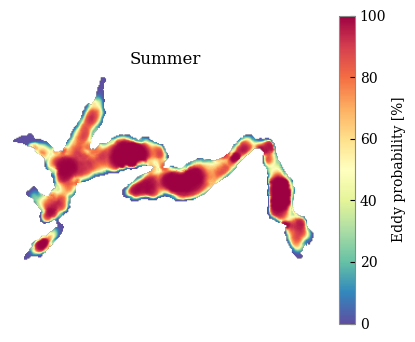

In [16]:
figsize=(5,4)
plt.figure(figsize=figsize)
plt.imshow(eddy_perc, cmap=sns.color_palette("Spectral_r", as_cmap=True), origin="lower", vmin=0, vmax=100)
cbar = plt.colorbar()
cbar.set_label("Eddy probability [%]")

#plt.text(0.98, 0.98, f'{str_depth_min}m to {str_depth_max}m', transform=plt.gca().transAxes, ha='right', va='top')
plt.grid(False)
plt.axis('off')

plt.title(f'{seasons[season_idx].capitalize()}')

# 4 seasons

### Surface layer

In [17]:
i_depth_min, i_depth_max = 0, 21 # 15m
str_depth_max = str(round(depths.iloc[i_depth_max]['depth_[m]'], 2))
str_depth_min = str(round(depths.iloc[i_depth_min]['depth_[m]'], 2))

In [18]:
eddy_perc_4seasons = []
for idx_season in range(4):
    start_date, end_date, Nt = get_season_dates(idx_season)
    eddy_perc_4seasons.append(get_eddy_perc(
        df, start_date, end_date,
        i_depth_min, i_depth_max, Nx, Ny
    ))

In [19]:
def get_fig_layout(lake):
    if lake == 'zug':
        fig = plt.figure(figsize=(8, 4), layout="constrained")
        gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 0.04])

        axes = [fig.add_subplot(gs[0, i]) for i in range(4)]
        cax = fig.add_subplot(gs[0, 4])
    if lake == 'neuchatel':
        fig = plt.figure(figsize=(5, 6), layout="constrained")
        gs = fig.add_gridspec(4, 2, width_ratios=[1, 0.04])

        axes = [fig.add_subplot(gs[i, 0]) for i in range(4)]
        cax = fig.add_subplot(gs[:, 1])
    if lake == 'lucerne':
        fig = plt.figure(figsize=(5, 10), layout="constrained")
        gs = fig.add_gridspec(4, 2, width_ratios=[1, 0.04])

        axes = [fig.add_subplot(gs[i, 0]) for i in range(4)]
        cax = fig.add_subplot(gs[:, 1])
    else:
        fig = plt.figure(figsize=(5, 12), layout="constrained")
        gs = fig.add_gridspec(4, 2, width_ratios=[1, 0.04])

        axes = [fig.add_subplot(gs[i, 0]) for i in range(4)]
        cax = fig.add_subplot(gs[:, 1])

    return fig, gs, axes, cax

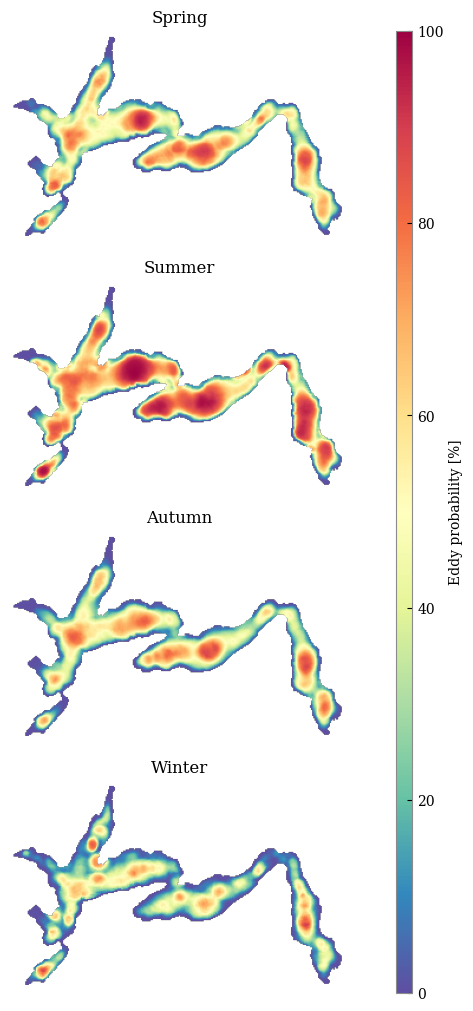

In [20]:
fig, gs, axes, cax = get_fig_layout(lake)
cmap = sns.color_palette("Spectral_r", as_cmap=True)

for idx_season, ax in enumerate(axes):
    start_date, end_date, Nt = get_season_dates(idx_season)
    eddy_perc = eddy_perc_4seasons[idx_season]

    im = ax.imshow(
        eddy_perc,
        cmap=cmap,
        origin="lower",
        vmin=0,
        vmax=100,
        aspect="equal",
    )

    ax.set_title(seasons[idx_season].capitalize())
    ax.set_axis_off()

cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Eddy probability [%]")

plt.show()

### Entire water column

In [21]:
i_depth_min, i_depth_max = 0, int(depths['depth_index'].max())
str_depth_max = str(round(depths.iloc[i_depth_max]['depth_[m]'], 2))
str_depth_min = str(round(depths.iloc[i_depth_min]['depth_[m]'], 2))

In [22]:
eddy_perc_4seasons = []
for idx_season in range(4):
    start_date, end_date, Nt = get_season_dates(idx_season)
    eddy_perc_4seasons.append(get_eddy_perc(
        df, start_date, end_date,
        i_depth_min, i_depth_max, Nx, Ny
    ))

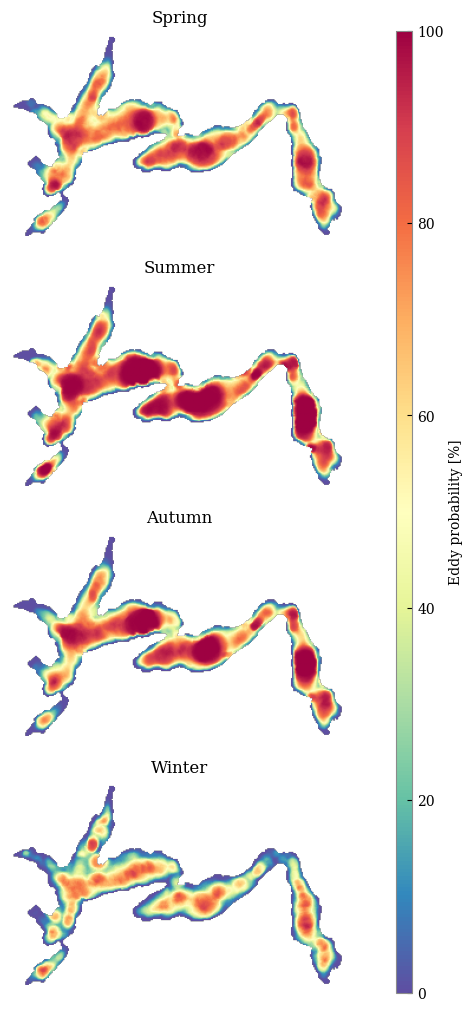

In [23]:
fig, gs, axes, cax = get_fig_layout(lake)
cmap = sns.color_palette("Spectral_r", as_cmap=True)

for idx_season, ax in enumerate(axes):
    start_date, end_date, Nt = get_season_dates(idx_season)
    eddy_perc = eddy_perc_4seasons[idx_season]

    im = ax.imshow(
        eddy_perc,
        cmap=cmap,
        origin="lower",
        vmin=0,
        vmax=100,
        aspect="equal",
    )

    ax.set_title(seasons[idx_season].capitalize())
    ax.set_axis_off()

cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Eddy probability [%]")

plt.show()